# Figure S5B — Peak RAM across versions and hardware

Peak resident memory (RSS) of the Python process while metapredict V1, V2 and V3 predict the human reference proteome on each hardware configuration.

**How it is made.** Same runs as Figure 1E (`data/benchmarks/proteome/`, metapredict 3.1.0 at its default per-device batch size). RSS is sampled every 0.1 s by a background thread during the timed prediction; repeat runs are summarised by their median. GB here is 2$^{30}$ bytes. For MPS runs the bars show host RSS only: on macOS, RSS does not include Metal (GPU) allocations, so V3 on MPS shows ~3.4 GB here although the MPS driver holds 23.2 GB (Figure S5C).

**Output:** `figures/figure_S05B.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import (grouped_version_bars, hardware_groups, hardware_label, median_by,
                        proteome_rows, version_legend)

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
rows = proteome_rows()
groups = hardware_groups(rows)
peak_ram_gb = median_by(rows, lambda r: (r['network_version'], hardware_label(r)), 'peak_rss_gb')

proteome: 12 rows from 12 files; metapredict (version, commit): [('3.1.0+6.ga1b28a7.dirty', '7dcf52c+dirty'), ('3.1.0+7.g7dcf52c.dirty', '7dcf52c+dirty')]


Wrote figures/figure_S05B.pdf


PosixPath('figures/figure_S05B.pdf')

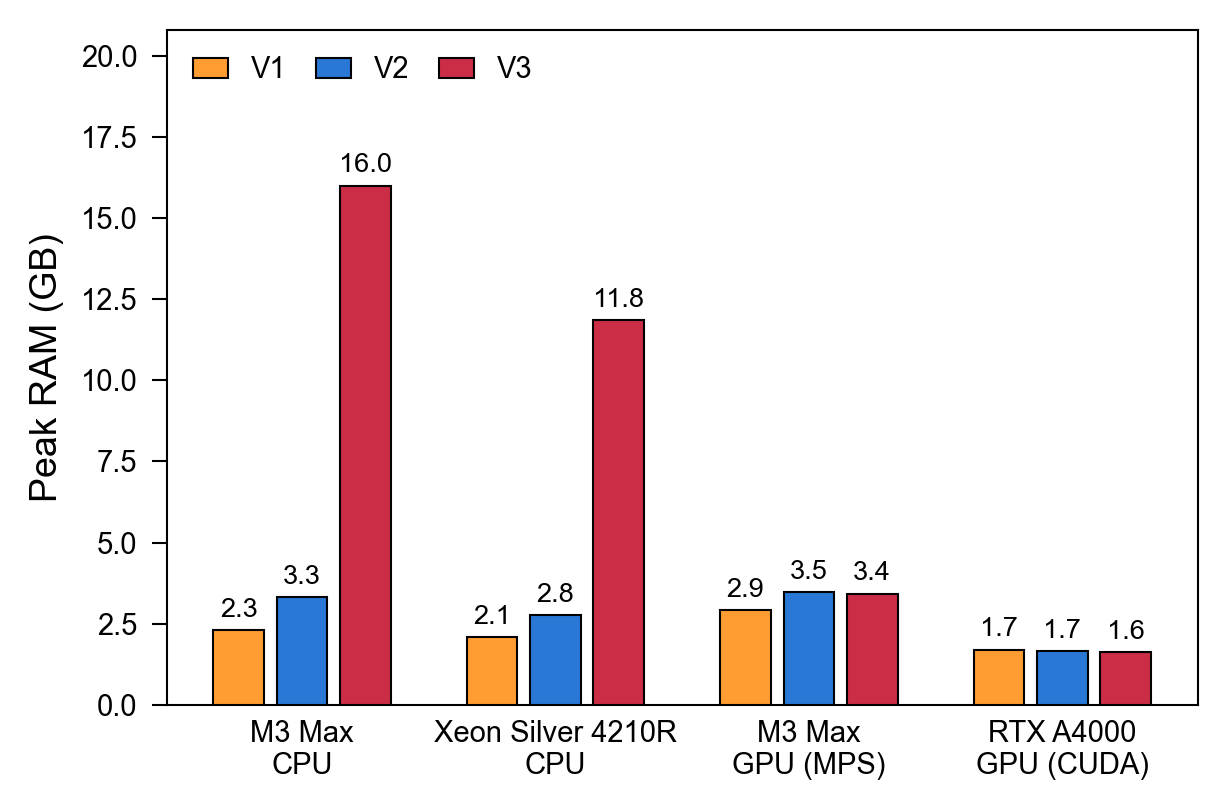

In [3]:
fig, ax = plt.subplots(figsize=(4.2, 2.8), dpi=150)
grouped_version_bars(ax, groups, peak_ram_gb, label_fmt=lambda v: f'{v:.1f}')
ax.set_ylim(0, max(peak_ram_gb.values()) * 1.3)
ax.set_ylabel('Peak RAM (GB)', fontsize=9)
version_legend(ax, loc='upper left', ncol=3)
plt.tight_layout()
save_panel(fig, 'figure_S05B')